In [1]:
import glob
import numpy as np
import os.path
import xarray as xr
from scipy import interpolate
import scipy.signal as signal
from netCDF4 import Dataset
from datetime import datetime
import time
import pandas as pd
import xgboost as xgb
from sklearn.utils import shuffle
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold, KFold,GroupKFold,LeaveOneGroupOut,StratifiedGroupKFold
from sklearn.model_selection import train_test_split, cross_val_score,cross_val_predict,permutation_test_score
from sklearn.metrics import accuracy_score, balanced_accuracy_score,roc_auc_score,classification_report,confusion_matrix
import pickle
import shap
import seaborn as sns
import matplotlib.pyplot as plt
import itertools

C:\Program Files\Anaconda3\lib\site-packages\pandas\core\computation\expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Program Files\Anaconda3\lib\site-packages\xarray\backends\cfgrib_.py:27: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(
C:\Program Files\Anaconda3\lib\site-packages\xgboost\compat.py:36: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


In [2]:
ref_mask_dir = 'S://atmos_disk//Luke_W_480//MPL_Christchurch_2021//A//processed{}/'
peaks_dir = 'S://atmos_disk//Luke_W_480//MPL_Christchurch_2021//B//peaks/'

In [3]:
print('Preparing peak dataset')
peaks_fpath = peaks_dir+'peaks_df_{}.csv'.format('2e-5')
peaks_df = pd.read_csv(peaks_fpath, index_col=[0])  

Preparing peak dataset


In [4]:
exclusion_dates = [
    20210518,
    ]

In [5]:
peaks_training = peaks_df[~peaks_df['date'].isin(exclusion_dates)]
peaks_training = peaks_training.query('amps_flag==1') # Required if training using SLCC

peaks_training = peaks_training.reset_index(drop=True)

In [6]:
# Select input and target variables for model training
VARS = [
    'peak_backscatter', 
    'peak_width',
    'peak_width_height',
    'peak_prominence',
    'peak_alt',
    'num_peaks',
    'peak_order',
    'peak_temp',
    ]

X = peaks_training[VARS]  

In [7]:
# TARGET = 'LCC_ij'
TARGET = 'SLCC_ij' # Need to uncomment peaks_training.query('amps_flag==1') above

Y = peaks_training[TARGET].astype(int)                       
                            
groups = peaks_training['date'].astype('str').str[:-2]

In [24]:
model = xgb.XGBClassifier(objective='binary:logistic',
                      booster='gbtree', n_jobs=-1,
                      use_label_encoder=False,verbosity=0)

# params = {'learning_rate': 0.02, 'max_depth': 6} # For SLCC_ij
model.set_params(**params)

XGBClassifier(base_score=None, booster='gbtree', colsample_bylevel=None,
              colsample_bynode=None, colsample_bytree=None,
              enable_categorical=False, gamma=None, gpu_id=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.02, max_delta_step=None, max_depth=6,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=100, n_jobs=-1, num_parallel_tree=None,
              predictor=None, random_state=None, reg_alpha=None,
              reg_lambda=None, scale_pos_weight=None, subsample=None,
              tree_method=None, use_label_encoder=False,
              validate_parameters=None, verbosity=0)

In [25]:
start_time = time.time()
model.fit(X,Y)
best_model = model
print("--- %s seconds ---" % (time.time() - start_time))

--- 1.8354759216308594 seconds ---


In [26]:
explainer = shap.Explainer(best_model)
shap_values = explainer(X)


ntree_limit is deprecated, use `iteration_range` or model slicing instead.


In [19]:
shap.initjs()

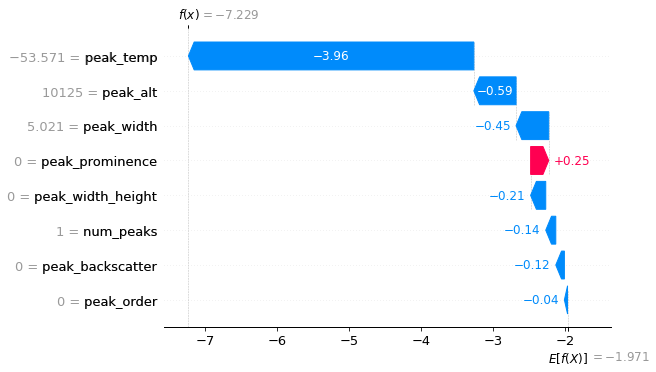

In [21]:
shap.plots.waterfall(shap_values[0]) 

In [24]:
shap.plots.force(shap_values[:100])

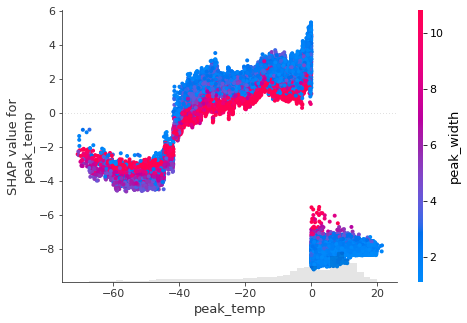

In [40]:
shap.plots.scatter(shap_values[:,"peak_temp"], color=shap_values[:, 'peak_width'])

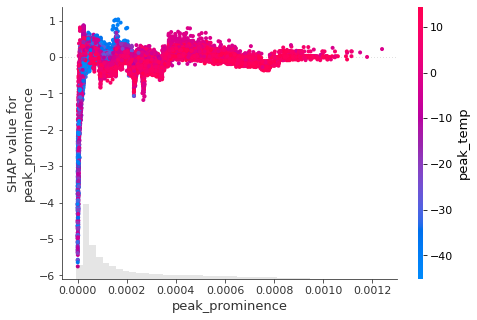

In [44]:
shap.plots.scatter(shap_values[:,"peak_prominence"], color=shap_values)

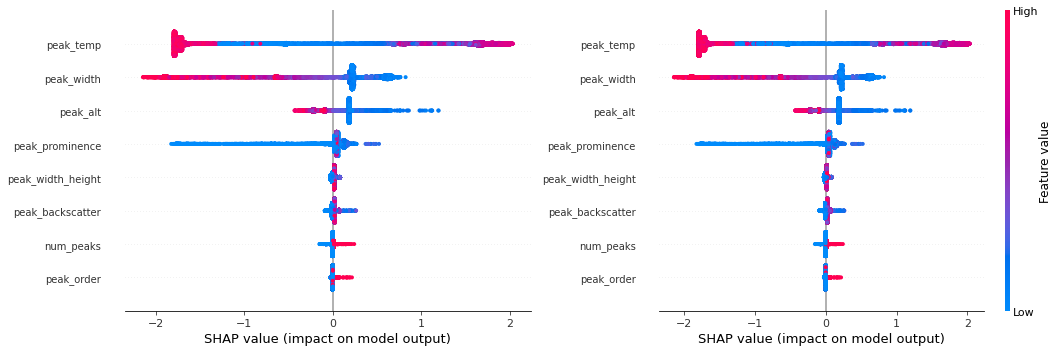

In [22]:
fig = plt.figure(figsize=(15,5))

ax1 = fig.add_subplot(121)
shap.plots.beeswarm(shap_values,show=False,color_bar=False,plot_size=None)

ax2= fig.add_subplot(122)
shap.plots.beeswarm(shap_values,show=False,plot_size=None)

ax1.tick_params(axis='y', labelsize=10)
ax2.tick_params(axis='y', labelsize=10)

plt.tight_layout()

In [18]:
shap.__version__

'0.40.0'

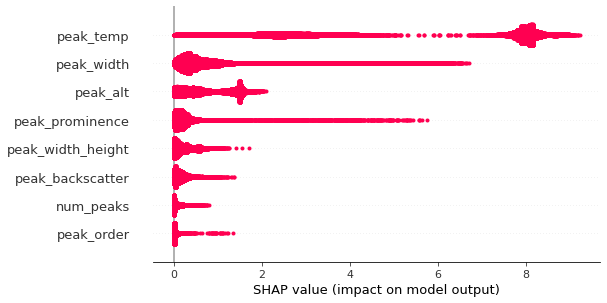

In [56]:
shap.plots.beeswarm(shap_values.abs, color="shap_red")

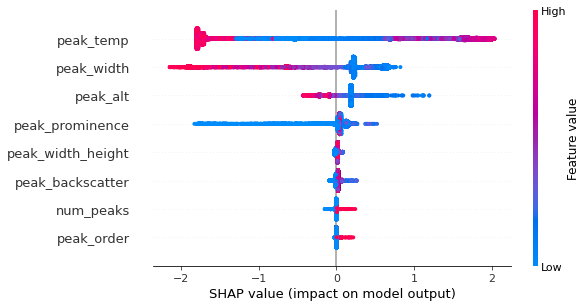

In [27]:
shap.summary_plot(shap_values,X)

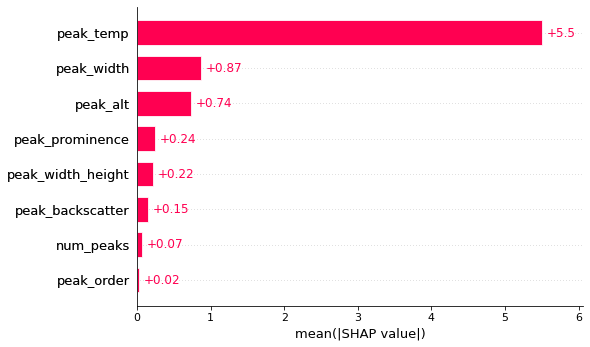

In [57]:
shap.plots.bar(shap_values)

In [66]:
shap_interaction = explainer.shap_interaction_values(X)

ntree_limit is deprecated, use `iteration_range` or model slicing instead.


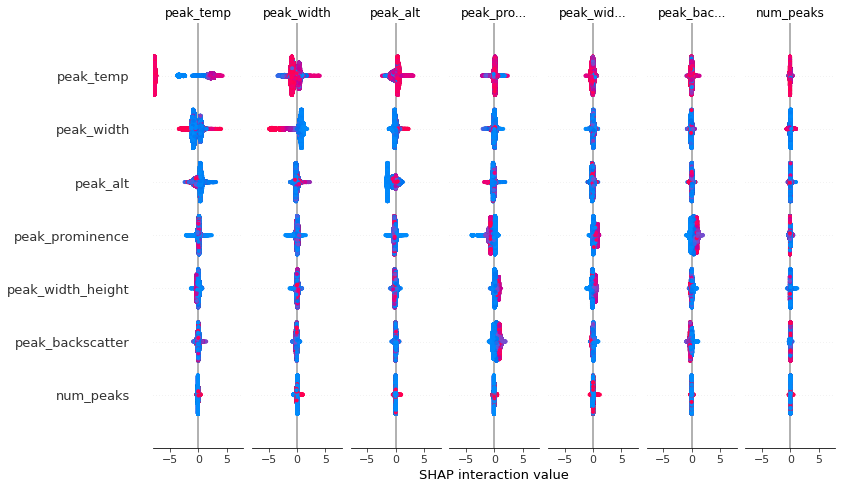

In [83]:
shap.summary_plot(shap_interaction, X)

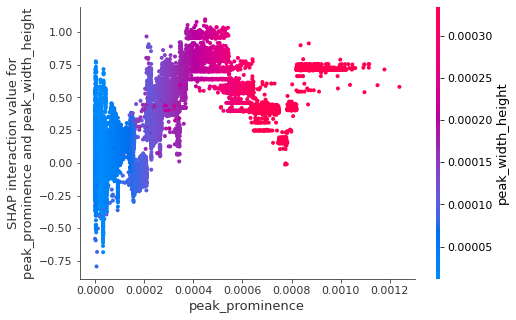

In [133]:
shap.dependence_plot(
    ("peak_prominence", "peak_width_height"),
    shap_interaction, X,
    display_features=X)


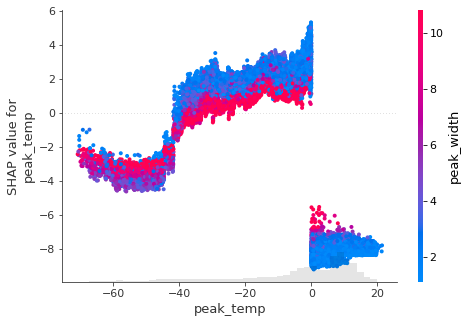

In [124]:
shap.plots.scatter(shap_values[:,"peak_temp"], color=shap_values[:, 'peak_width'])

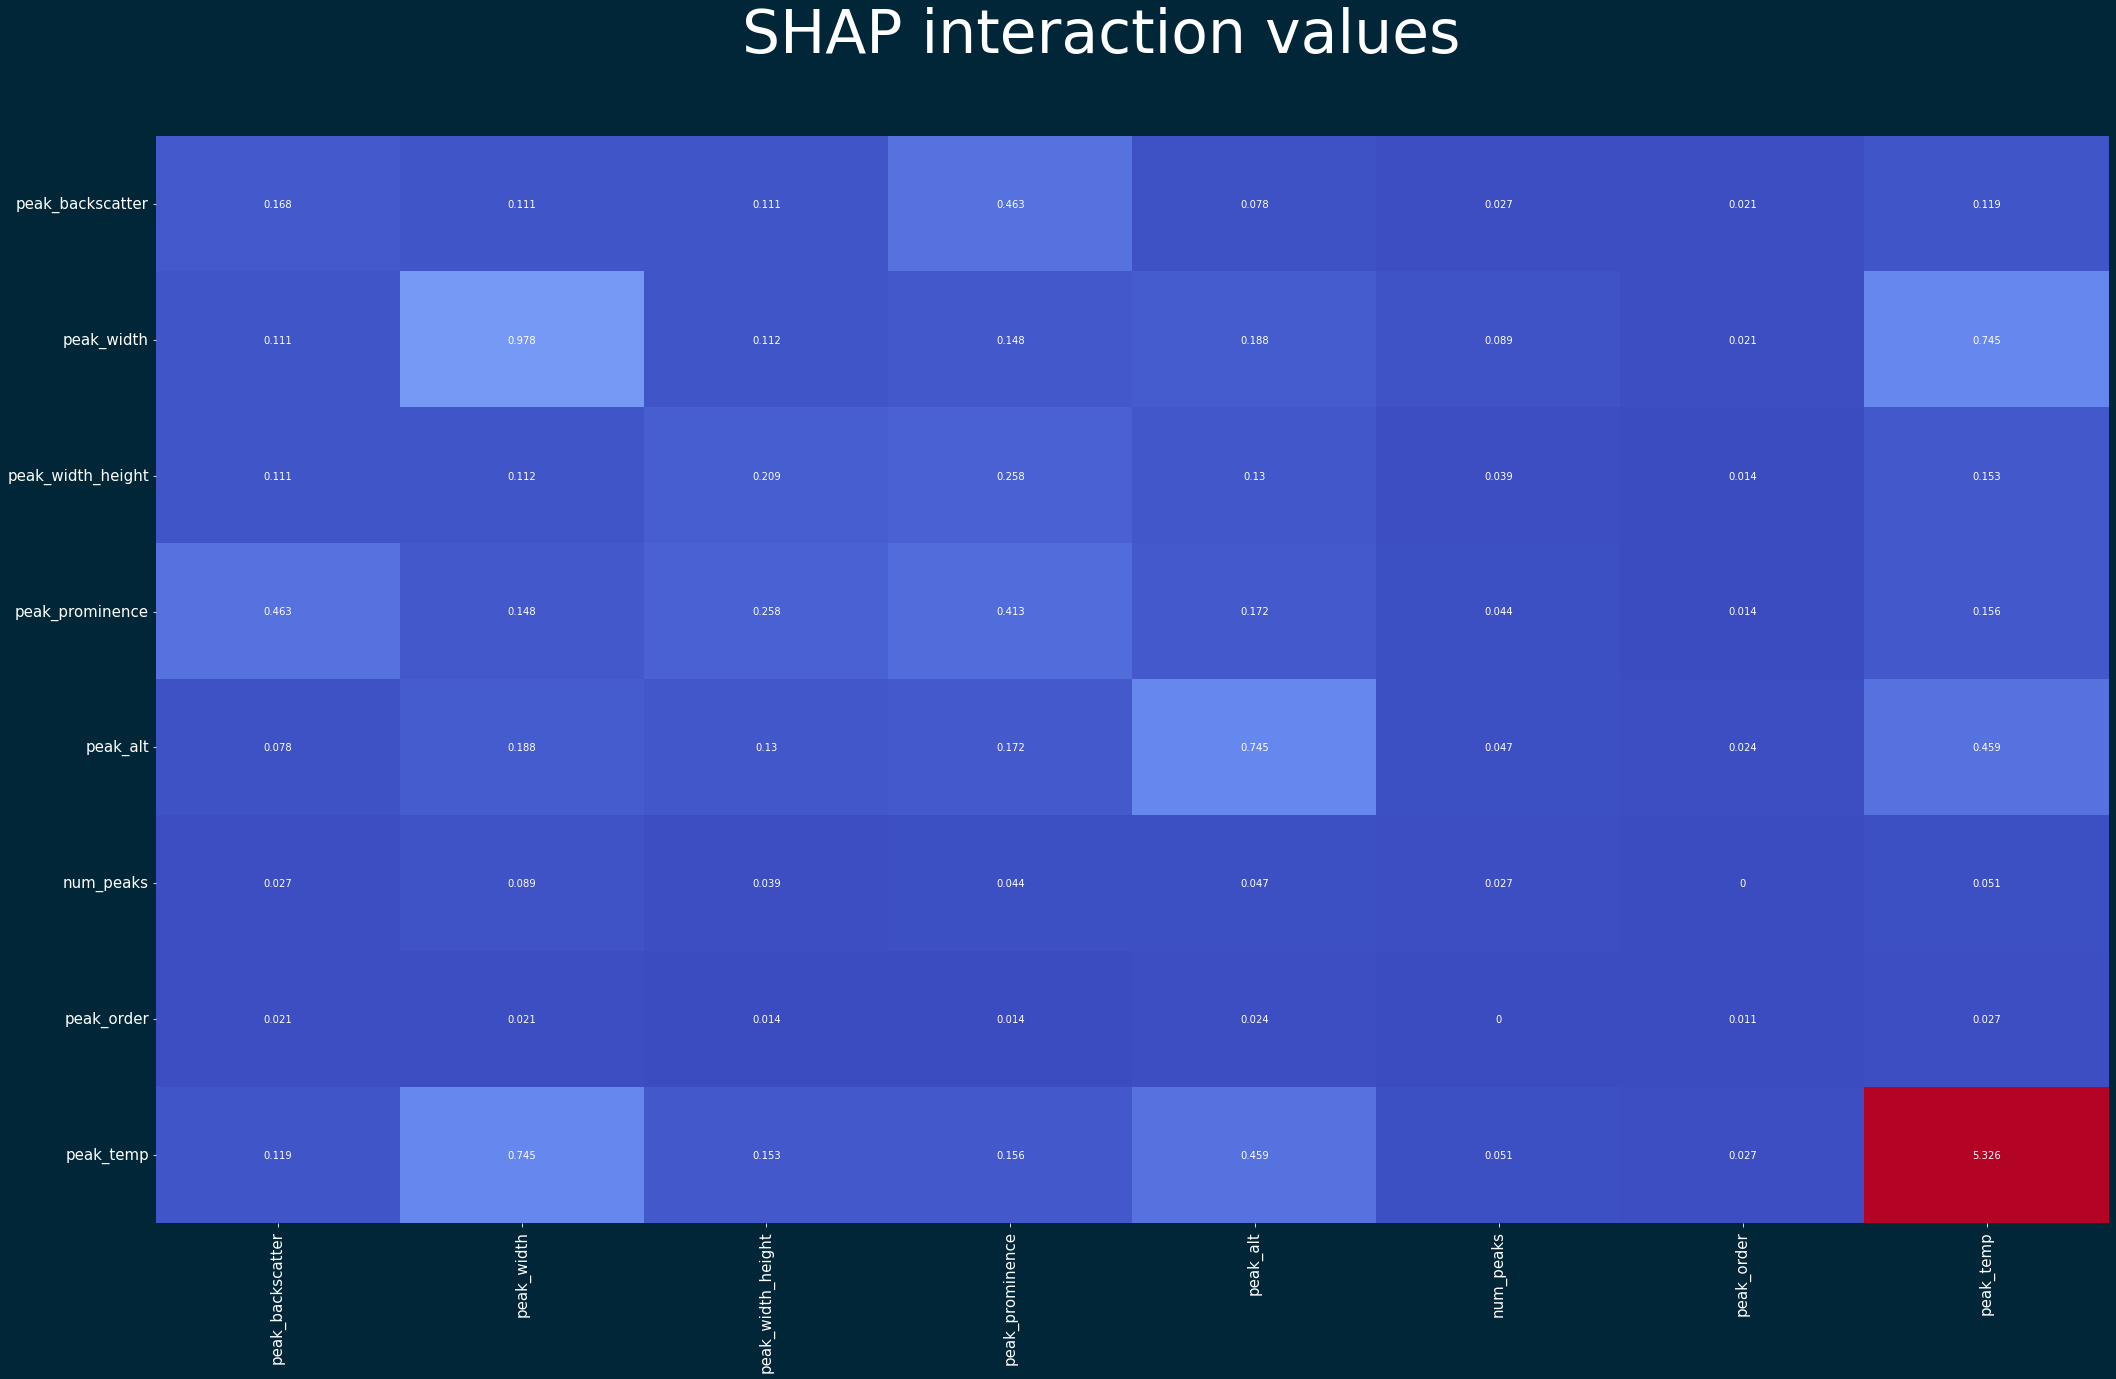

In [109]:
# Get absolute mean of matrices
mean_shap = np.abs(shap_interaction).mean(0)
df = pd.DataFrame(mean_shap, index=X.columns, columns=X.columns)

# times off diagonal by 2
df.where(df.values == np.diagonal(df),df.values*2, inplace=True)

# display 
fig = plt.figure(figsize=(35, 20), facecolor='#002637', edgecolor='r')
ax = fig.add_subplot()
sns.heatmap(df.round(decimals=3), cmap='coolwarm', annot=True, fmt='.6g', cbar=False, ax=ax, )
ax.tick_params(axis='x', colors='w', labelsize=15, rotation=90)
ax.tick_params(axis='y', colors='w', labelsize=15)

plt.suptitle("SHAP interaction values", color="white", fontsize=60, y=0.97)
plt.yticks(rotation=0) 
plt.show()

In [112]:
import matplotlib.gridspec as gridspec


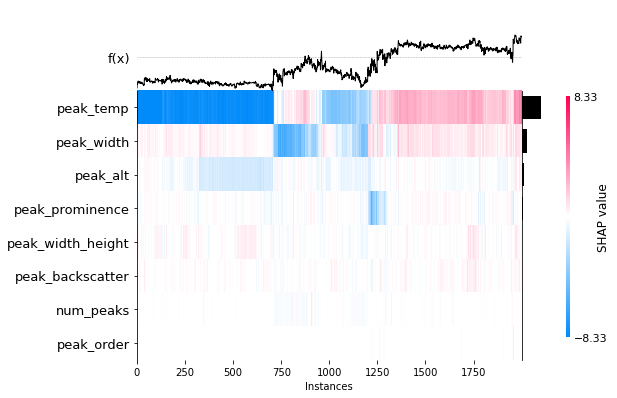

In [131]:
shap.plots.heatmap(shap_values[:2000])


In [130]:
np.shape(shap_values)


(37175, 8)